Dataset Head:

   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Abbay

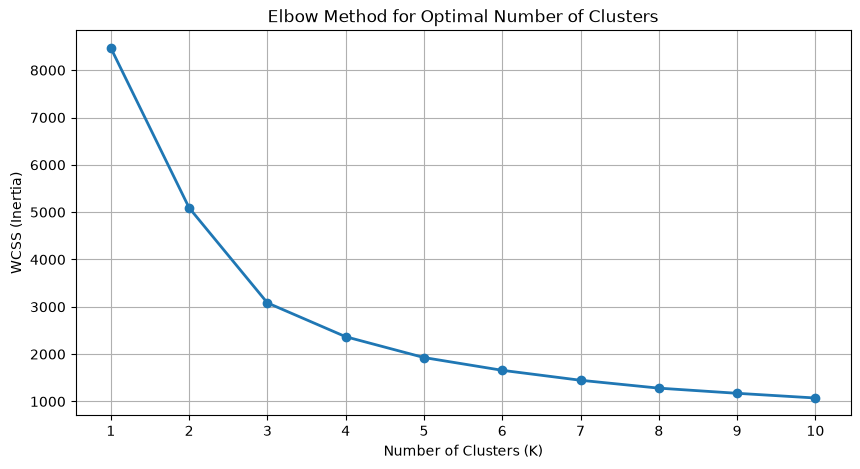


K-Means Clustered Data:

   QUANTITYORDERED  PRICEEACH    SALES  KMeans_Cluster
0               30      95.70  2871.00             2.0
1               34      81.35  2765.90             2.0
2               41      94.74  3884.34             0.0
3               45      83.26  3746.70             0.0
4               49     100.00  5205.27             0.0


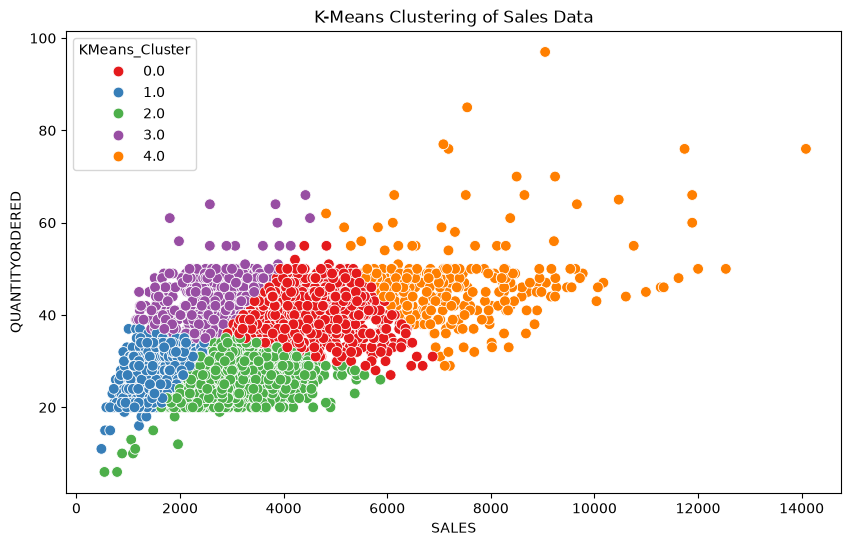

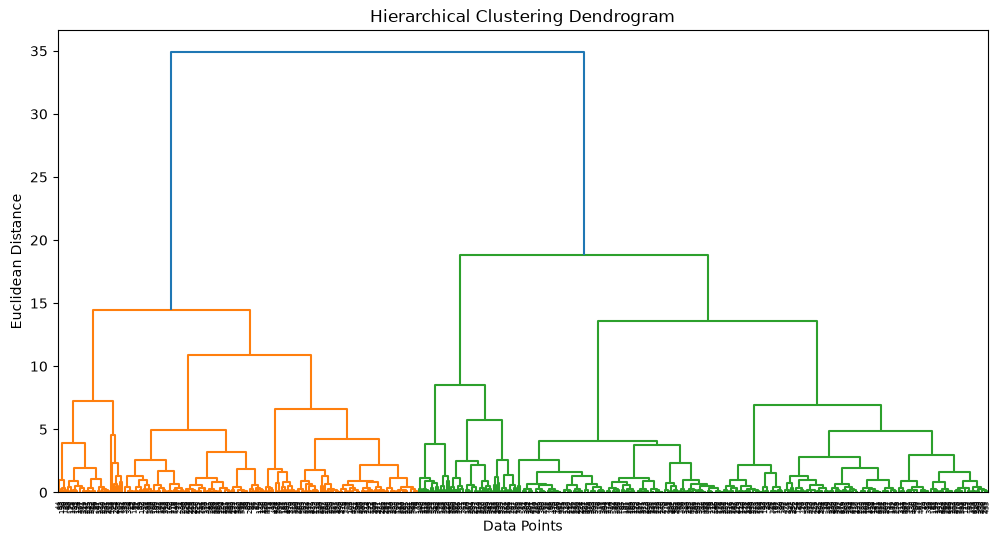

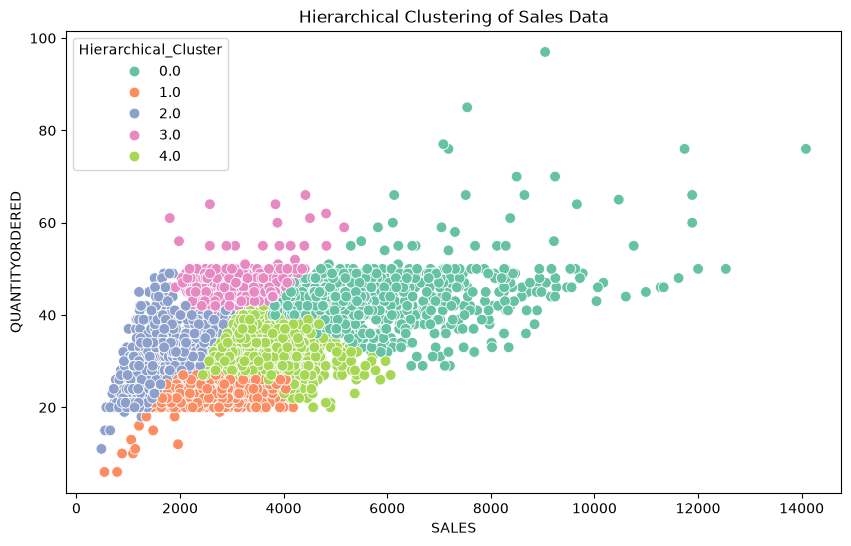


K-Means Cluster Summary:

                QUANTITYORDERED  PRICEEACH        SALES
KMeans_Cluster                                         
0.0                   40.399183  95.908801  4535.907916
1.0                   27.398833  57.976323  1578.356576
2.0                   26.175460  96.226798  3039.853055
3.0                   43.353982  59.350442  2568.105509
4.0                   46.759740  99.740065  7317.315682

Hierarchical Cluster Summary:

                      QUANTITYORDERED  PRICEEACH        SALES
Hierarchical_Cluster                                         
0.0                         44.083212  99.451168  6081.749635
1.0                         22.836100  93.625083  2536.622739
2.0                         31.515556  56.471304  1769.684222
3.0                         46.657817  68.074956  3170.703333
4.0                         32.356698  96.138925  3698.711698


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage

# ---------------------------------------------------------
# 1. Load Dataset & Basic EDA
# ---------------------------------------------------------

data = pd.read_csv('sales_data_sample.csv', encoding='latin1')

print("Dataset Head:\n")
print(data.head())

print("\nDataset Shape:", data.shape)

print("\nDataset Columns:\n")
print(data.columns)


# ---------------------------------------------------------
# 2. Select Features for Clustering
# ---------------------------------------------------------

# Selecting numerical sales-related features
X = data[[
    "QUANTITYORDERED",
    "PRICEEACH",
    "SALES"
]]

# Remove missing values
X = X.dropna()

print("\nSelected Features:\n")
print(X.head())


# ---------------------------------------------------------
# 3. Feature Scaling
# ---------------------------------------------------------

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)


# ---------------------------------------------------------
# 4. Finding Optimal K using Elbow Method
# ---------------------------------------------------------

wcss = []

for k in range(1, 11):

    km = KMeans(
        n_clusters=k,
        init="k-means++",
        random_state=42,
        n_init=10
    )

    km.fit(X_scaled)

    wcss.append(km.inertia_)


# ---------------------------------------------------------
# 5. Plotting Elbow Curve
# ---------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, 11),
    wcss,
    linewidth=2,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS (Inertia)")
plt.title("Elbow Method for Optimal Number of Clusters")

plt.xticks(range(1, 11))
plt.grid()

plt.show()


# ---------------------------------------------------------
# 6. K-Means Clustering
# ---------------------------------------------------------

# Select optimal K based on Elbow Graph
# Change this value according to the elbow point
optimal_k = 5


kmeans = KMeans(
    n_clusters=optimal_k,
    init="k-means++",
    random_state=42,
    n_init=10
)

# Predict clusters
clusters = kmeans.fit_predict(X_scaled)

# Add cluster labels to dataset
data.loc[X.index, "KMeans_Cluster"] = clusters


print("\nK-Means Clustered Data:\n")
print(data[[
    "QUANTITYORDERED",
    "PRICEEACH",
    "SALES",
    "KMeans_Cluster"
]].head())


# ---------------------------------------------------------
# 7. Visualizing K-Means Clusters (2D)
# ---------------------------------------------------------

plt.figure(figsize=(10, 6))

sns.scatterplot(
    x="SALES",
    y="QUANTITYORDERED",
    hue="KMeans_Cluster",
    palette="Set1",
    data=data,
    s=60
)

plt.title("K-Means Clustering of Sales Data")

plt.show()


# ---------------------------------------------------------
# 8. Hierarchical Clustering - Dendrogram
# ---------------------------------------------------------

# Using a sample for faster dendrogram visualization
sample_size = min(500, len(X_scaled))

X_sample = X_scaled[:sample_size]


plt.figure(figsize=(12, 6))

linked = linkage(X_sample, method="ward")

dendrogram(linked)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Euclidean Distance")

plt.show()


# ---------------------------------------------------------
# 9. Hierarchical Clustering
# ---------------------------------------------------------

hierarchical = AgglomerativeClustering(
    n_clusters=optimal_k,
    linkage="ward"
)

hierarchical_clusters = hierarchical.fit_predict(X_scaled)

data.loc[X.index, "Hierarchical_Cluster"] = hierarchical_clusters


# ---------------------------------------------------------
# 10. Visualizing Hierarchical Clusters
# ---------------------------------------------------------

plt.figure(figsize=(10, 6))

sns.scatterplot(
    x="SALES",
    y="QUANTITYORDERED",
    hue="Hierarchical_Cluster",
    palette="Set2",
    data=data,
    s=60
)

plt.title("Hierarchical Clustering of Sales Data")

plt.show()


# ---------------------------------------------------------
# 11. Cluster Summary
# ---------------------------------------------------------

print("\nK-Means Cluster Summary:\n")

print(
    data.groupby("KMeans_Cluster")[
        ["QUANTITYORDERED", "PRICEEACH", "SALES"]
    ].mean()
)


print("\nHierarchical Cluster Summary:\n")

print(
    data.groupby("Hierarchical_Cluster")[
        ["QUANTITYORDERED", "PRICEEACH", "SALES"]
    ].mean()
)